# ДЗ 2. Наложение и удаление шума

Наложение гауссова и постоянного шума. Проверка медианного, гауссовского, билатерального фильтров и NLM по MSE и SSIM.

In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import mean_squared_error, structural_similarity

rng = np.random.default_rng(42)

image_path = Path('sar_1.jpg')
if not image_path.exists():
    image_path = Path('D:/DownLoads/sar_1.jpg')

## 1. Наложение шума

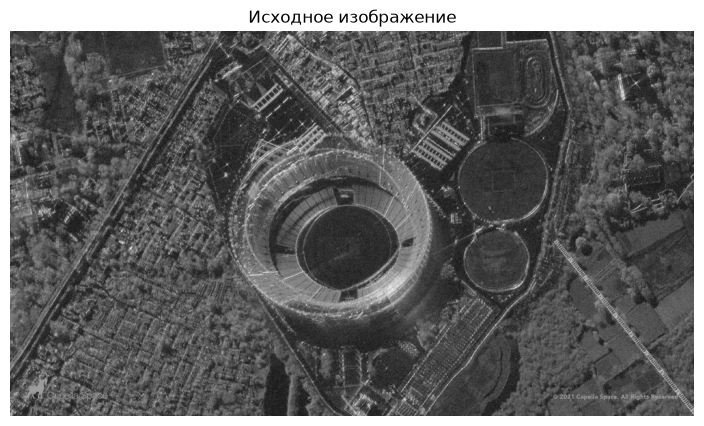

In [2]:
image = cv2.imread(str(image_path))
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
roi = (slice(230, 480), slice(350, 750))

plt.figure(figsize=(10, 5))
plt.imshow(image_gray, cmap='gray', vmin=0, vmax=255)
plt.title('Исходное изображение')
plt.axis('off');

In [3]:
stddev = 50
b = int(round(stddev * np.sqrt(1.5)))

noise_gauss = rng.normal(0, stddev, image_gray.shape)
noise_gauss = np.clip(noise_gauss, 0, 255).astype(np.uint8)
noise_uniform = rng.integers(0, b + 1, image_gray.shape, dtype=np.uint8)

image_noise_gauss = cv2.add(image_gray, noise_gauss)
image_noise_uniform = cv2.add(image_gray, noise_uniform)

print('stddev =', stddev, 'b =', b)

stddev = 50 b = 61


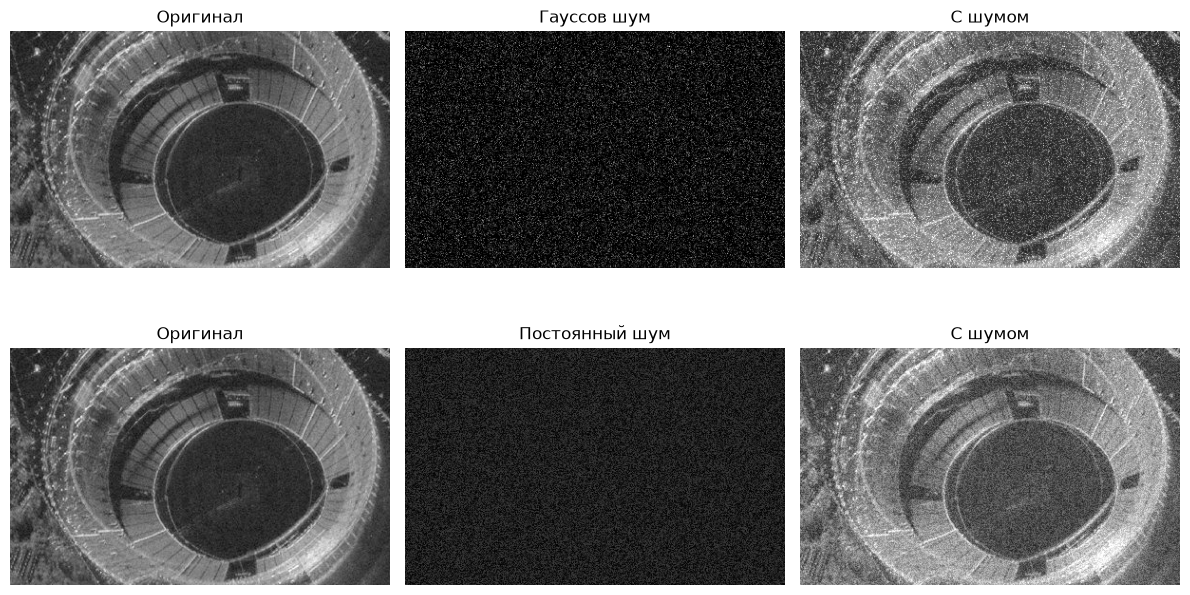

In [4]:
fig, ax = plt.subplots(2, 3, figsize=(12, 7))

for row, (name, noise, noisy) in enumerate([
    ('Гауссов шум', noise_gauss, image_noise_gauss),
    ('Постоянный шум', noise_uniform, image_noise_uniform)
]):
    ax[row, 0].imshow(image_gray[roi], cmap='gray', vmin=0, vmax=255)
    ax[row, 0].set_title('Оригинал')
    ax[row, 1].imshow(noise[roi], cmap='gray', vmin=0, vmax=255)
    ax[row, 1].set_title(name)
    ax[row, 2].imshow(noisy[roi], cmap='gray', vmin=0, vmax=255)
    ax[row, 2].set_title('С шумом')

for item in ax.ravel():
    item.axis('off')
plt.tight_layout()

In [5]:
def metrics(reference, image):
    mse = mean_squared_error(reference, image)
    ssim = structural_similarity(reference, image, data_range=255)
    return mse, ssim

for name, noisy in [('gauss', image_noise_gauss), ('uniform', image_noise_uniform)]:
    mse, ssim = metrics(image_gray, noisy)
    print(f'{name:8} MSE = {mse:.1f}, SSIM = {ssim:.3f}')

gauss    MSE = 1219.9, SSIM = 0.413
uniform  MSE = 1249.2, SSIM = 0.581


## 2. Проверка фильтров

In [6]:
def apply_filter(image, filter_name, params):
    if filter_name == 'median':
        return cv2.medianBlur(image, params[0])
    if filter_name == 'gaussian':
        return cv2.GaussianBlur(image, (params[0], params[0]), params[1])
    if filter_name == 'bilateral':
        return cv2.bilateralFilter(image, *params)
    return cv2.fastNlMeansDenoising(image, None, params[0], 7, 21)

variants = {
    'median': [(3,), (5,), (7,)],
    'gaussian': [(3, 0), (5, 0), (7, 1)],
    'bilateral': [(9, 50, 50), (9, 75, 75)],
    'nlm': [(10,), (20,), (30,)]
}

noises = {'gauss': image_noise_gauss, 'uniform': image_noise_uniform}
results = []

for noise_name, noisy in noises.items():
    mse, ssim = metrics(image_gray, noisy)
    results.append([noise_name, 'без фильтра', '-', mse, ssim, noisy])
    for filter_name, params_list in variants.items():
        for params in params_list:
            filtered = apply_filter(noisy, filter_name, params)
            mse, ssim = metrics(image_gray, filtered)
            results.append([noise_name, filter_name, str(params), mse, ssim, filtered])

In [7]:
for noise_name in noises:
    print('\nШум:', noise_name)
    print(f"{'Фильтр':14} {'Параметры':16} {'MSE':>10} {'SSIM':>8}")
    print('-' * 54)
    for row in results:
        if row[0] == noise_name:
            print(f'{row[1]:14} {row[2]:16} {row[3]:10.1f} {row[4]:8.3f}')


Шум: gauss
Фильтр         Параметры               MSE     SSIM
------------------------------------------------------
без фильтра    -                    1219.9    0.413
median         (3,)                  367.7    0.639
median         (5,)                  371.0    0.571
median         (7,)                  416.9    0.488
gaussian       (3, 0)                569.0    0.667
gaussian       (5, 0)                559.3    0.663
gaussian       (7, 1)                556.8    0.668
bilateral      (9, 50, 50)           539.8    0.570
bilateral      (9, 75, 75)           524.6    0.583
nlm            (10,)                1219.8    0.413
nlm            (20,)                 685.1    0.577
nlm            (30,)                 589.9    0.510

Шум: uniform
Фильтр         Параметры               MSE     SSIM
------------------------------------------------------
без фильтра    -                    1249.2    0.581
median         (3,)                 1091.0    0.634
median         (5,)             

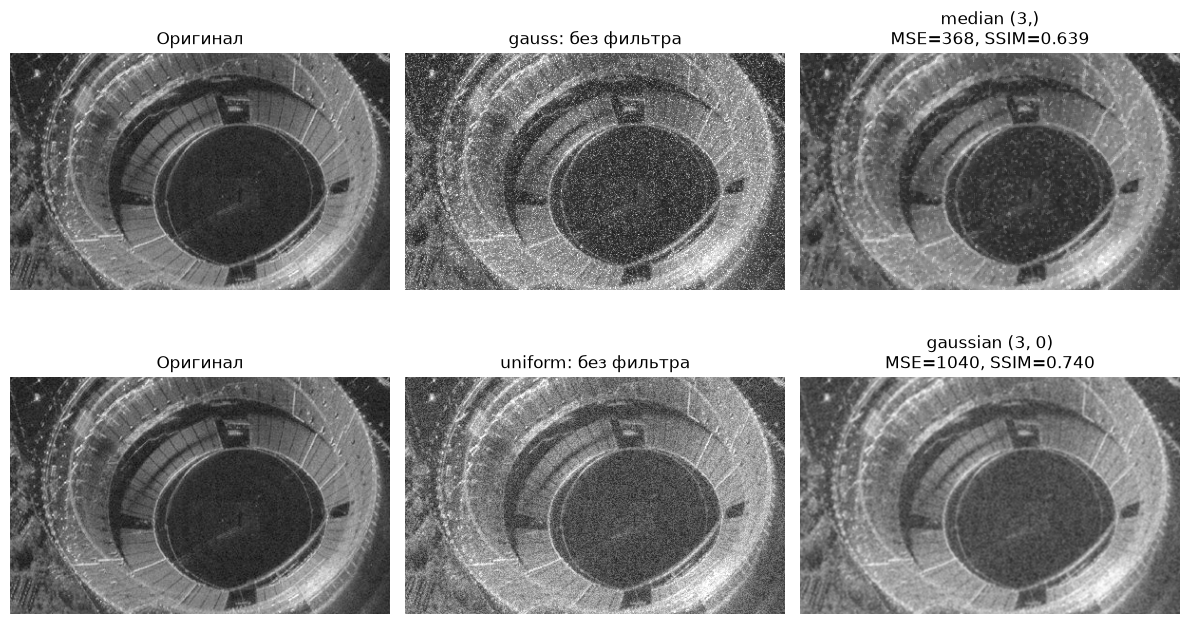

In [8]:
def best_result(noise_name):
    rows = [row for row in results if row[0] == noise_name and row[1] != 'без фильтра']
    return min(rows, key=lambda row: row[3])

fig, ax = plt.subplots(2, 3, figsize=(12, 7))

for row_num, noise_name in enumerate(noises):
    noisy = noises[noise_name]
    best = best_result(noise_name)
    ax[row_num, 0].imshow(image_gray[roi], cmap='gray', vmin=0, vmax=255)
    ax[row_num, 0].set_title('Оригинал')
    ax[row_num, 1].imshow(noisy[roi], cmap='gray', vmin=0, vmax=255)
    ax[row_num, 1].set_title(f'{noise_name}: без фильтра')
    ax[row_num, 2].imshow(best[5][roi], cmap='gray', vmin=0, vmax=255)
    ax[row_num, 2].set_title(f'{best[1]} {best[2]}\nMSE={best[3]:.0f}, SSIM={best[4]:.3f}')

for item in ax.ravel():
    item.axis('off')
plt.tight_layout()

## 3. Вывод

In [9]:
for noise_name in noises:
    rows = [row for row in results if row[0] == noise_name and row[1] != 'без фильтра']
    best_mse = min(rows, key=lambda row: row[3])
    best_ssim = max(rows, key=lambda row: row[4])
    print(f'\n{noise_name}:')
    print(f'Лучший MSE: {best_mse[1]} {best_mse[2]} -> {best_mse[3]:.1f}')
    print(f'Лучший SSIM: {best_ssim[1]} {best_ssim[2]} -> {best_ssim[4]:.3f}')


gauss:
Лучший MSE: median (3,) -> 367.7
Лучший SSIM: gaussian (7, 1) -> 0.668

uniform:
Лучший MSE: gaussian (3, 0) -> 1040.1
Лучший SSIM: gaussian (3, 0) -> 0.740


По MSE лучше выбирать вариант с минимальным значением, а по SSIM - с максимальным. Для разных типов шума лучшие параметры могут отличаться.